# Garment Worker Productivity - Data Audit

This notebook is used to explore the garment worker productivity dataset and check the quality of the data before preprocessing and modelling it.

## 1. Loading the Dataset

The dataset is loaded using pandas so that it can be explored and analysed as a DataFrame.

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [ ]:
# Loads garment productivity dataset
df = pd.read_csv("../data/garments_worker_productivity.csv")

# Displays first five rows
df.head()

,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
0,1/1/2015,Quarter1,sweing,Thursday,8,0.80,26.16,1108.0,7080,98,0.0,0,0,59.0,0.940725
1,1/1/2015,Quarter1,finishing,Thursday,1,0.75,3.94,NaN,960,0,0.0,0,0,8.0,0.886500
2,1/1/2015,Quarter1,sweing,Thursday,11,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
3,1/1/2015,Quarter1,sweing,Thursday,12,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
4,1/1/2015,Quarter1,sweing,Thursday,6,0.80,25.90,1170.0,1920,50,0.0,0,0,56.0,0.800382


## 2. Dataset Structure

The next checks look at the size of the dataset, the available columns and the type of data stored in each variable.

In [ ]:
# Check for the number of rows and columns in dataset
df.shape

(1197, 15)

In [ ]:
# Displays the column names
df.columns

Index(['date', 'quarter', 'department', 'day', 'team', 'targeted_productivity',
       'smv', 'wip', 'over_time', 'incentive', 'idle_time', 'idle_men',
       'no_of_style_change', 'no_of_workers', 'actual_productivity'],
      dtype='str')

In [ ]:
# Displays information about each column and its data type
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1197 entries, 0 to 1196
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   date                   1197 non-null   str    
 1   quarter                1197 non-null   str    
 2   department             1197 non-null   str    
 3   day                    1197 non-null   str    
 4   team                   1197 non-null   int64  
 5   targeted_productivity  1197 non-null   float64
 6   smv                    1197 non-null   float64
 7   wip                    691 non-null    float64
 8   over_time              1197 non-null   int64  
 9   incentive              1197 non-null   int64  
 10  idle_time              1197 non-null   float64
 11  idle_men               1197 non-null   int64  
 12  no_of_style_change     1197 non-null   int64  
 13  no_of_workers          1197 non-null   float64
 14  actual_productivity    1197 non-null   float64
dtypes: float64(6), 

### Initial Observations

The dataset contains 1,197 records and 15 columns. The variables include both numerical and categorical data. Most columns are complete, although the `wip` column appears to contain missing values. The target variable for this project is `actual_productivity`.

## 3. Data Quality Checks

The dataset is checked for missing values and duplicate records before preprocessing. These checks help identify data quality issues that may need to be handled before training the models.

In [ ]:
# Checks the number of duplicate rows
df.duplicated().sum()

np.int64(0)

In [ ]:
# Checks number of missing values in each column
df.isnull().sum()

date                       0
quarter                    0
department                 0
day                        0
team                       0
targeted_productivity      0
smv                        0
wip                      506
over_time                  0
incentive                  0
idle_time                  0
idle_men                   0
no_of_style_change         0
no_of_workers              0
actual_productivity        0
dtype: int64

### Quality of Data Observations

The dataset contains no duplicate rows. The `wip` column has 506 missing values, while all other columns are complete. These missing values will need to be considered during preprocessing before the machine learning models are trained.

## 4. Target Variable

The target variable for this project is `actual_productivity`. The following code looks at its range and distribution.

### 4.1 Statistic Summary

In [15]:
# Target variable statistics summary
df["actual_productivity"].describe()

count    1197.000000
mean        0.735091
std         0.174488
min         0.233705
25%         0.650307
50%         0.773333
75%         0.850253
max         1.120437
Name: actual_productivity, dtype: float64

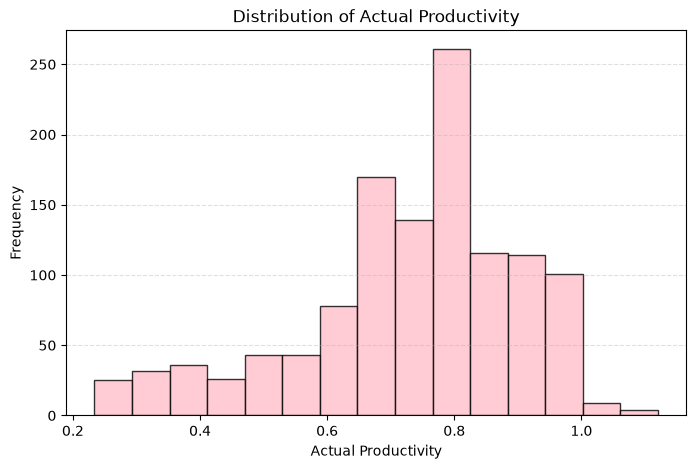

In [28]:
# Histogram that displays the distribution of actual productivity values

plt.figure(figsize=(8, 5))

plt.hist(
    df["actual_productivity"],
    bins=15,
    color="pink",
    edgecolor="black",
    alpha=0.8
)
plt.xlabel("Actual Productivity")
plt.ylabel("Frequency")
plt.title("Distribution of Actual Productivity")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.show()

### Target Variable Observations

Most actual productivty values are concentrated between approximately 0.6 and 1.0, with the highest frequency around 0.75 to 0.8. There are fewer observations at the lower end of the distribution and only a small number of values are above 1. Thesee higher values will be considered again when chekcing for unusual values or outliers.

### 4.2 Checking for Unusual Values

A box plot is used to check whether the target variable contains values that are unusually high or low compared with the rest of the dataset.

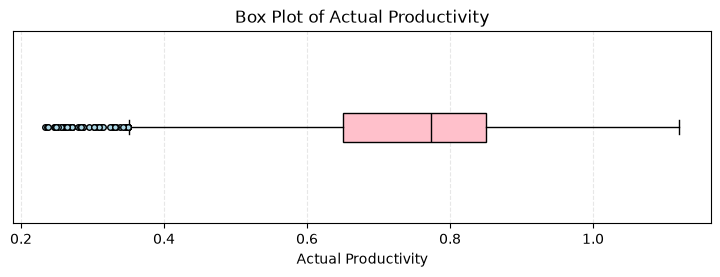

In [27]:
# Displays a box plot to check for unusual actual productivity values

plt.figure(figsize=(9, 2.5))

plt.boxplot(
    df["actual_productivity"],
    orientation="horizontal",
    patch_artist=True,
    boxprops=dict(facecolor="pink"),
    medianprops=dict(color="black"),
    flierprops=dict(
        marker="o",
        markerfacecolor="lightblue",
        markeredgecolor="black",
        markersize=4
    )
)

plt.xlabel("Actual Productivity")
plt.title("Box Plot of Actual Productivity")
plt.yticks([])
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.show()

### Outliers Observations

The box plot confirms that most actual productivity values are concentrated between approximately 0.65 and 0.85, with the median around 0.77. Several lower productivity values, roughly below 0.35, are potential outliers. For now these values will not be removed because they may represent genuine low-productivity observations rather than errors in the data.

## 5. Feature Checks

The input features are checked to identify unusual values and to understand the numerical and categorical variables better before preprocessing.


### 5.1 Numerical features

In [22]:
# Displays summary statistics for the numerical features
df.describe().T

,count,mean,std,min,25%,50%,75%,max
team,1197.0,6.426901,3.463963,1.000000,3.000000,6.000000,9.000000,12.000000
targeted_productivity,1197.0,0.729632,0.097891,0.070000,0.700000,0.750000,0.800000,0.800000
smv,1197.0,15.062172,10.943219,2.900000,3.940000,15.260000,24.260000,54.560000
wip,691.0,1190.465991,1837.455001,7.000000,774.500000,1039.000000,1252.500000,23122.000000
over_time,1197.0,4567.460317,3348.823563,0.000000,1440.000000,3960.000000,6960.000000,25920.000000
incentive,1197.0,38.210526,160.182643,0.000000,0.000000,0.000000,50.000000,3600.000000
idle_time,1197.0,0.730159,12.709757,0.000000,0.000000,0.000000,0.000000,300.000000
idle_men,1197.0,0.369256,3.268987,0.000000,0.000000,0.000000,0.000000,45.000000
no_of_style_change,1197.0,0.150376,0.427848,0.000000,0.000000,0.000000,0.000000,2.000000
no_of_workers,1197.0,34.609858,22.197687,2.000000,9.000000,34.000000,57.000000,89.000000


### Numerical Feature Observations

The numerical features have quite different ranges. The `wip` variable contains fewer values because of the missing data identified earlier and it also has some much larger values compared with its median. `over_time` also has a wide range. The features `incentive`, `idle_time` and `idle_men` are zero for many records but contain some much larger values. These values will be kept for now and considered again during preprocessing and later analysis.

### 5.2 Categorical features

In [24]:
# Checks the amount of unique values are present in the categorical features
df[["quarter", "department", "day"]].nunique()

quarter       5
department    3
day           6
dtype: int64

In [26]:
# Displays the categories with their frequencies
for column in ["quarter", "department", "day"]:
    print(f"\n{column}:")
    print(df[column].value_counts())


quarter:
quarter
Quarter1    360
Quarter2    335
Quarter4    248
Quarter3    210
Quarter5     44
Name: count, dtype: int64

department:
department
sweing        691
finishing     257
finishing     249
Name: count, dtype: int64

day:
day
Wednesday    208
Sunday       203
Tuesday      201
Thursday     199
Monday       199
Saturday     187
Name: count, dtype: int64


### Categorical Feature Observations

The categorical features contain a small number of categories overall. The `department` column appears to contain two versions of the `finishing` category, which suggests that inconsistent spacing may be present and will need to be cleaned during preprocessing. `Quarter5` occurs less frequently than the other quarters and the day categories are fairly evenly distributed.